In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:46255")
client

<Client: 'tcp://127.0.0.1:46255' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

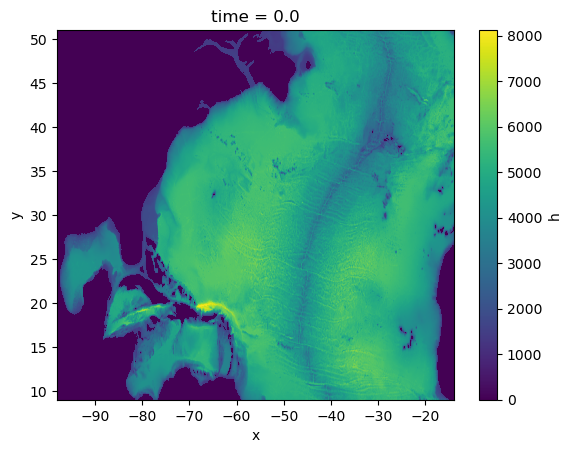

In [6]:
ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % 1)
                    )
ds.h.isel(time=0).sum("level").plot(rasterized=True)

In [9]:
ds.h.isel(time=0).sum("level").to_dataset(name="H"
                                         ).to_zarr(op.join(ddir,"SW/bathy.zarr"),
                                                   mode="w")

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


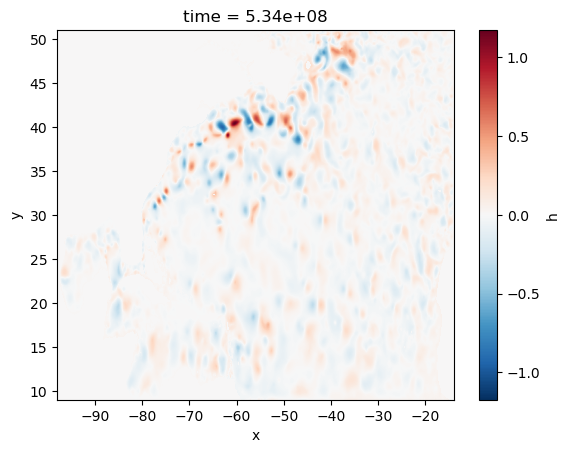

In [8]:
ds.h.sum("level").diff("time").dropna("time").isel(time=-1).plot(rasterized=True)

In [4]:
H = xr.open_zarr(op.join(ddir,"SW/bathy.zarr")).H

for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>

In [5]:
# ssh = ds.h.sum("level") - H
# print(ssh)
# ssh.to_dataset(name="ssh").chunk({"time":4}).to_zarr(op.join(ddir,"SW/SSH.zarr"), mode="w")
ssh = xr.open_zarr(op.join(ddir,"SW/SSH.zarr")).ssh
ssh

<xarray.DataArray 'ssh' (time: 630, y: 2048, x: 4096)> Size: 21GB
dask.array<open_dataset-ssh, shape=(630, 2048, 4096), dtype=float32, chunksize=(4, 128, 256), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01

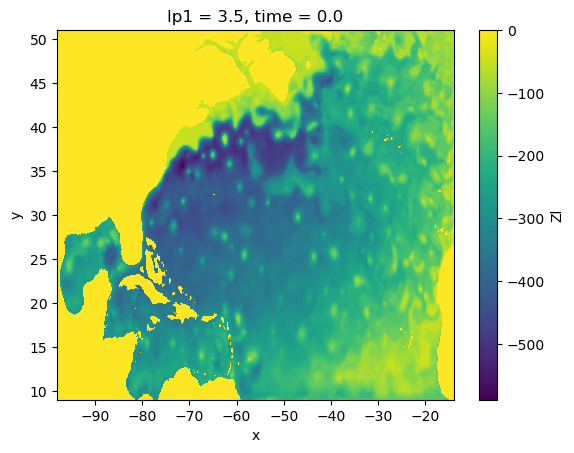

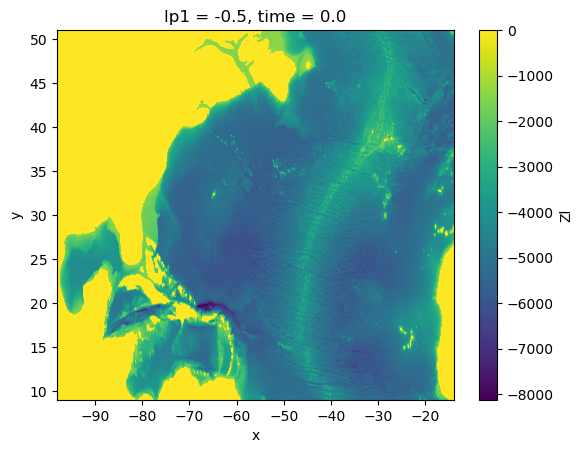

In [8]:
# Z = ssh - xr.DataArray(np.cumsum(ds.h.data[:,::-1],axis=1),
#                        dims=["time","lp1","y","x"], 
#                        coords={"lp1":np.arange(4,-1,-1)-.5}
#                       ).sortby("lp1")
# print(Z)
# Z.to_dataset(name="Zl").chunk({"time":4}).to_zarr(op.join(ddir,"SW/Zl.zarr"), 
#                                                   mode="w")
dszl = xr.open_zarr(op.join(ddir,"SW/Zl.zarr"))
dszl.Zl.isel(time=0,lp1=-1).plot(rasterized=True)
plt.show()
dszl.Zl.isel(time=0,lp1=0).plot(rasterized=True)
plt.show()

<xarray.DataArray 'mul-b8f8fb95690878aac144941aae4f7d92' (time: 630, y: 2048,
                                                          x: 4096, level: 5)> Size: 106GB
dask.array<mul, shape=(630, 2048, 4096, 5), dtype=float32, chunksize=(4, 128, 256, 4), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 21.89 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


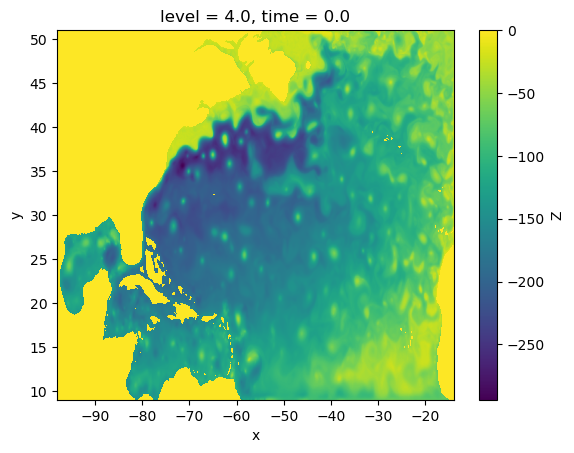

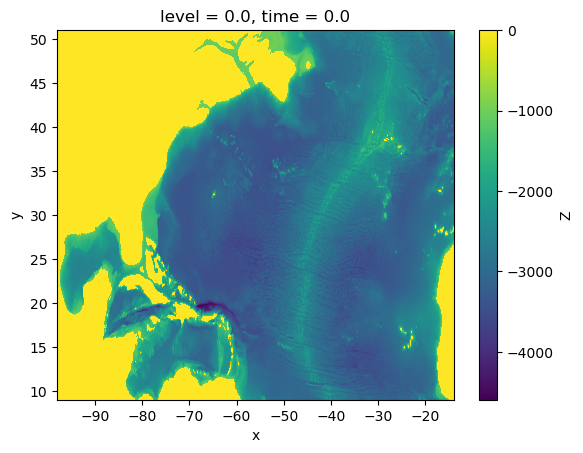

In [9]:
Z = xr.concat([dszl.Zl, 
               xr.DataArray(ssh.data[:,:,:,np.newaxis],
                            dims=dszl.Zl.dims, 
                            coords={"lp1":np.array([4.5,])})
              ], "lp1")
# Z = xr.concat([xr.DataArray(-H.data[:,:,:,np.newaxis],
#                             dims=dszl.Zl.dims, 
#                             coords={"lp1":np.array([-.5,])}), 
#                xr.concat([dszl.Zl.isel(lp1=slice(1,None)), 
#                           xr.DataArray(ssh.data[:,:,:,np.newaxis],
#                                        dims=dszl.Zl.dims, 
#                                        coords={"lp1":np.array([4.5,])})
#                          ], "lp1")
#               ], "lp1")
Z = xr.DataArray(.5*(Z.isel(lp1=slice(1,None)).data
                     + Z.isel(lp1=slice(None,-1)).data
                    ), dims=["time","y","x","level"], 
                 coords=ds.h.coords
                )
print(Z)
Z.to_dataset(name="Z").chunk({"time":4}).to_zarr(op.join(ddir,"SW/Z.zarr"), 
                                                 mode="w")
dsz = xr.open_zarr(op.join(ddir,"SW/Z.zarr"))
dsz.Z.isel(time=0,level=-1).plot(rasterized=True)
plt.show()
dsz.Z.isel(time=0,level=0).plot(rasterized=True)
plt.show()